[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/roberthsu2003/PythonForDataAnalysis/blob/master/%E6%97%A5%E6%9C%9F%E5%92%8C%E6%99%82%E9%96%93/%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90/%E7%AF%84%E4%BE%8B_%E8%8C%B6%E8%AA%9E%E6%99%82%E5%85%89_%E5%85%A9%E5%B9%B4%E7%87%9F%E6%94%B6%E8%88%87%E5%A4%96%E9%80%81%E6%99%82%E5%8D%80.ipynb)

# 📅 茶語時光：兩年營收趨勢與外送時區之謎

> 🧋 **情境**：品牌成立滿兩年，董事會想看：「今年比去年成長多少？哪個月最好？颱風到底讓我們少賺多少？」同時，外送部門抱怨：「平台報表說我們凌晨 4 點最忙，這怎麼可能？」你要用 pandas 的時間工具，一次解開這些問題。

| 素材檔案 | 內容 |
| --- | --- |
| `每日營收_2023-2024.csv` | 2023～2024 兩年、5 家門市的每日杯數與營收（日期格式是「2024/1/5」的文字） |
| `外送訂單_UTC_2024-09.csv` | 9 月外送平台訂單，時間以 UTC（世界標準時間）儲存 |

> ⚠️ 「茶語時光」是課程虛構的品牌，資料為模擬資料；節日與颱風假的日期參考台灣實際情況，方便你對照生活經驗。

## 🗺️ 今日任務地圖

| 關卡 | 要回答的問題 |
| --- | --- |
| ⬜ 任務 1 | 文字變日期——星期幾生意最好？ |
| ⬜ 任務 2 | 每日 → 每月——resample 做月報 |
| ⬜ 任務 3 | 月增率與年增率——今年到底成長多少？ |
| ⬜ 任務 4 | rolling 移動平均——把「颱風日」自動抓出來 |
| ⬜ 任務 5 | 外送時區之謎——凌晨 4 點最忙？ |
| ⬜ 任務 6 | 季度報表——to_period |

**怎麼用這本 Notebook**：從上到下按 `Shift + Enter` 一格一格執行。每個任務都會先講「老闆想知道什麼」，再給程式，最後用 💡 **看懂結果** 告訴你這個數字代表什麼。

In [1]:
# 📦 準備素材：在 Colab 開啟時，自動下載本章素材壓縮檔並解壓縮
#    （若是在自己電腦解壓縮後開啟，檔案已經在旁邊，會直接使用）
import os, zipfile, urllib.request

FILES = [
    '每日營收_2023-2024.csv',
    '外送訂單_UTC_2024-09.csv',
]
ZIP_URL = 'https://github.com/roberthsu2003/PythonForDataAnalysis/raw/master/%E6%97%A5%E6%9C%9F%E5%92%8C%E6%99%82%E9%96%93/%E6%97%A5%E6%9C%9F%E5%92%8C%E6%99%82%E9%96%93_%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90.zip'

if not all(os.path.exists(f) for f in FILES):
    urllib.request.urlretrieve(ZIP_URL, 'materials.zip')            # 下載本章素材壓縮檔
    with zipfile.ZipFile('materials.zip') as z:
        for name in z.namelist():
            inner = name.split('/', 1)[1] if '/' in name else name   # 去掉壓縮檔最外層的資料夾名稱
            if inner and not name.endswith('/'):
                os.makedirs(os.path.dirname(inner) or '.', exist_ok=True)
                with z.open(name) as src, open(inner, 'wb') as dst:
                    dst.write(src.read())

print('✅ 素材準備完成：', [f for f in FILES if os.path.exists(f)])

✅ 素材準備完成： ['每日營收_2023-2024.csv', '外送訂單_UTC_2024-09.csv']


In [2]:
# --- 設定 Matplotlib 中文字型支援（Mac / Windows / Colab 通用）---
%pip install -q mplfonts

import glob, os
import mplfonts
from matplotlib import font_manager
from mplfonts import use_font

for f in glob.glob(os.path.join(os.path.dirname(mplfonts.__file__), "fonts", "*.[ot]tf")):
    font_manager.fontManager.addfont(f)   # 直接註冊 mplfonts 內附的字型，不改任何檔案
use_font("Noto Sans CJK SC")              # 套用思源黑體，負號也會一起處理

/private/tmp/claude-501/-Users-roberthsu2003-Documents-GitHub-PythonForDataAnalysis/a2ce4768-05fa-40ab-bf51-d29fa66026ee/scratchpad/venv/bin/python: No module named pip


Note: you may need to restart the kernel to use updated packages.


## 任務 1：文字變日期——星期幾生意最好？

**白話說明**：「2024/1/5」只是文字，要先用 `pd.to_datetime` 轉成真正的日期，才能取出星期幾、月份、季度。

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

daily = pd.read_csv('每日營收_2023-2024.csv')
print('轉換前的型態：', daily['日期'].dtype, daily['日期'].iloc[0])
daily['日期'] = pd.to_datetime(daily['日期'], format='%Y/%m/%d')       # 指定格式：年/月/日
print('轉換後的型態：', daily['日期'].dtype)

daily['星期'] = daily['日期'].dt.day_of_week                             # 0 = 星期一 … 6 = 星期日
week = daily.pivot_table(index='星期', columns='門市', values='杯數', aggfunc='mean').round(0)
week.index = ['一', '二', '三', '四', '五', '六', '日']
display(week)

轉換前的型態： str 2023/1/1
轉換後的型態： datetime64[us]


門市,台中逢甲店,台北信義店,台北西門店,台南成大店,高雄巨蛋店
一,392.0,393.0,326.0,320.0,317.0
二,374.0,383.0,317.0,324.0,308.0
三,392.0,392.0,337.0,327.0,318.0
四,396.0,381.0,340.0,319.0,327.0
五,508.0,415.0,413.0,340.0,378.0
六,590.0,291.0,550.0,304.0,475.0
日,532.0,254.0,533.0,288.0,426.0


## 任務 2：每日 → 每月——resample 做月報

門市,台中逢甲店,台北信義店,台北西門店,台南成大店,高雄巨蛋店,全品牌
日期,,,,,,
2024-07-31,91.3,78.4,87.5,66.6,72.1,395.9
2024-08-31,102.8,80.3,91.6,66.8,76.3,417.8
2024-09-30,87.6,73.3,82.5,63.2,73.0,379.5
2024-10-31,80.2,63.0,70.0,57.2,66.7,337.0
2024-11-30,76.9,56.8,66.1,53.2,61.1,314.2
2024-12-31,75.1,54.4,61.7,51.6,66.5,309.3


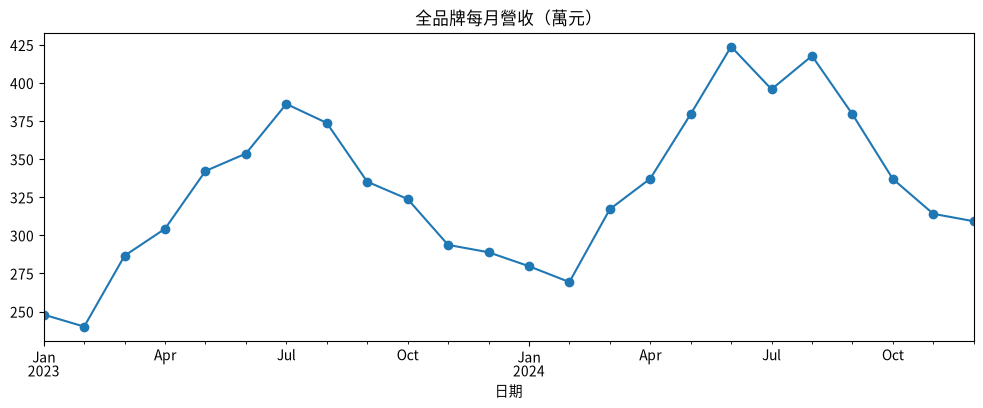

In [4]:
wide = daily.pivot(index='日期', columns='門市', values='營收')         # 日期當索引，才能用 resample
monthly = wide.resample('ME').sum()                                     # 'ME'＝每月月底彙總（新版 pandas 寫法，舊版是 'M'）
monthly['全品牌'] = monthly.sum(axis=1)
display((monthly / 10000).round(1).tail(6))

(monthly['全品牌'] / 10000).plot(figsize=(12, 4), marker='o', title='全品牌每月營收（萬元）')
plt.show()

## 任務 3：月增率與年增率——今年到底成長多少？

**白話說明**：
- **月增率（MoM）**：和「上個月」比 → `pct_change()`
- **年增率（YoY）**：和「去年同月」比 → `pct_change(12)`（往前 12 個月）

季節性很強的生意（飲料夏天好賣），**看年增率才公平**——拿 7 月和 6 月比沒有意義，拿今年 7 月和去年 7 月比才有意義。

In [5]:
brand = monthly['全品牌']
growth = pd.DataFrame({'營收(萬)': (brand / 10000).round(1),
                       '月增率%': (brand.pct_change() * 100).round(1),
                       '年增率%': (brand.pct_change(12) * 100).round(1)})
display(growth.loc['2024'])                                              # 只看 2024 年（日期索引可以直接用年份字串篩選）
print('\n2024 全年營收年成長：', round((brand['2024'].sum() / brand['2023'].sum() - 1) * 100, 1), '%')

,營收(萬),月增率%,年增率%
日期,,,
2024-01-31,279.8,-3.2,12.8
2024-02-29,269.4,-3.7,12.2
2024-03-31,317.2,17.7,10.6
2024-04-30,337.3,6.3,10.8
2024-05-31,379.6,12.6,10.9
2024-06-30,423.9,11.7,19.8
2024-07-31,395.9,-6.6,2.5
2024-08-31,417.8,5.5,11.8
2024-09-30,379.5,-9.2,13.2



2024 全年營收年成長： 10.2 %


> 💡 **看懂結果**：月增率忽正忽負（受季節影響），但年增率每個月都是正的——**品牌真的在成長**。7 月和 10 月的年增率特別低：2024 年 7 月有凱米颱風、10 月有山陀兒與康芮兩個颱風；6 月年增率最高，因為推出了「每週三第二杯半價」活動。
>
> 🤖 **換你問 AI**：「請把每日營收用 resample 彙總成每月，計算月增率與年增率，並說明為什麼季節性產業要看年增率。」

## 任務 4：rolling 移動平均——把「颱風日」自動抓出來

**白話說明**：用前後 15 天的移動平均當作「正常水準」，某天的營收如果低於正常水準的 60%，就標記為異常日。

異常低的日子：
 日期
2024-07-24    0.34
2024-07-25    0.26
2024-10-03    0.53
2024-10-31    0.23
dtype: float64


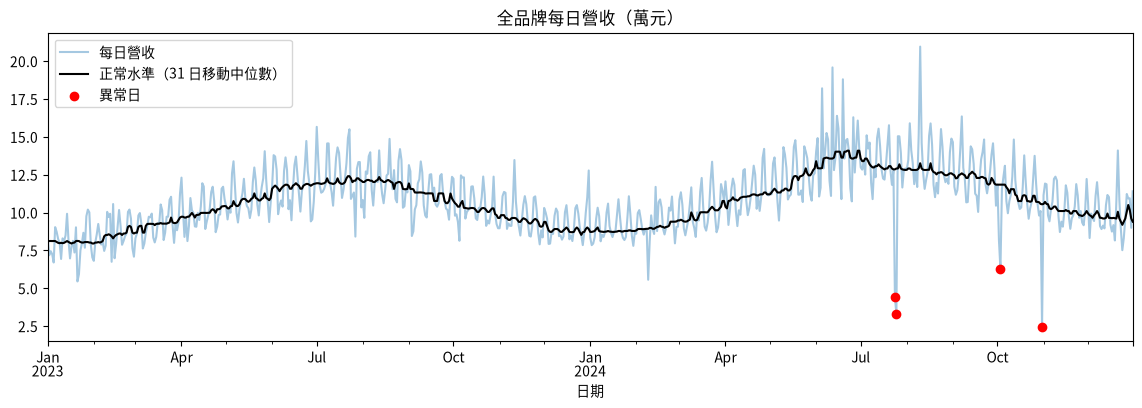

異常日估計少賺： 317,162 元


In [6]:
brand_daily = wide.sum(axis=1)                                          # 全品牌每日營收
normal = brand_daily.rolling(31, center=True, min_periods=10).median() # 前後 15 天的中位數 = 正常水準
ratio = brand_daily / normal
abnormal = ratio[ratio < 0.6]
print('異常低的日子：\n', abnormal.round(2))

ax = (brand_daily / 10000).plot(figsize=(14, 4), alpha=0.4, label='每日營收')
(normal / 10000).plot(ax=ax, color='black', label='正常水準（31 日移動中位數）')
ax.scatter(abnormal.index, brand_daily[abnormal.index] / 10000, color='red', zorder=3, label='異常日')
ax.legend(); ax.set_title('全品牌每日營收（萬元）')
plt.show()

loss = (normal[abnormal.index] - brand_daily[abnormal.index]).sum()
print('異常日估計少賺：', f'{loss:,.0f}', '元')

> 💡 **看懂結果**：程式自動抓出的 4 個異常日，全部都是全國性的颱風假：凱米（7/24、7/25）、山陀兒（10/3）、康芮（10/31）——**不用人工翻行事曆，數據自己會告訴你哪天出事了**。（只影響南部兩家店的颱風，全品牌合計沒有跌破 60%，所以沒被抓到；想抓得更細，可以改成每家店分開偵測。）把「估計少賺的金額」放進報告，就能說服老闆投保營業中斷險或強化外送。

## 任務 5：外送時區之謎——凌晨 4 點最忙？

**白話說明**：外送平台用 **UTC（世界標準時間）** 記錄時間，台灣是 **UTC+8**。沒有轉換時區，所有時間都差了 8 小時。

,訂單編號,下單時間_UTC,平台,門市,金額
0,UB004653,2024-09-01T02:33:28Z,FoodRun,高雄巨蛋店,102
1,UB000851,2024-09-01T02:34:37Z,FoodRun,高雄巨蛋店,258
2,UB000755,2024-09-01T02:38:05Z,FoodRun,台中逢甲店,153


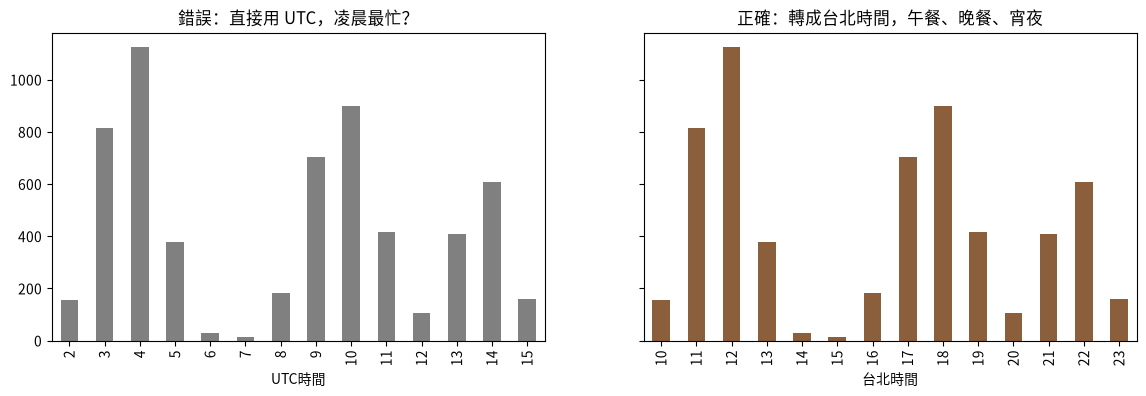

In [7]:
delivery = pd.read_csv('外送訂單_UTC_2024-09.csv')
display(delivery.head(3))

delivery['UTC時間'] = pd.to_datetime(delivery['下單時間_UTC'], utc=True)          # 標記為 UTC 時間
delivery['台北時間'] = delivery['UTC時間'].dt.tz_convert('Asia/Taipei')           # 轉換成台北時間

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
delivery['UTC時間'].dt.hour.value_counts().sort_index().plot.bar(ax=axes[0], color='gray', title='錯誤：直接用 UTC，凌晨最忙？')
delivery['台北時間'].dt.hour.value_counts().sort_index().plot.bar(ax=axes[1], color='#8B5E3C', title='正確：轉成台北時間，午餐、晚餐、宵夜')
plt.show()

> 💡 **看懂結果**：轉換時區後，三個高峰清清楚楚：**中午 12 點、晚上 6 點、宵夜 10 點**。外送人力與備料應該照右邊的圖安排，而不是左邊！
>
> 🤖 **換你問 AI**：「這份外送訂單的時間是 UTC（格式如 2024-09-01T04:12:00Z），請轉成台北時間，並畫出每小時訂單數長條圖。」

## 任務 6：季度報表——to_period

In [8]:
quarter = monthly.drop(columns='全品牌').resample('QE').sum()           # 每季彙總（'QE'＝季底）
quarter.index = quarter.index.to_period('Q')                            # 2024-03-31 → 2024Q1，報表更好讀
display((quarter / 10000).round(0))

門市,台中逢甲店,台北信義店,台北西門店,台南成大店,高雄巨蛋店
日期,,,,,
2023Q1,189.0,142.0,155.0,135.0,154.0
2023Q2,240.0,191.0,214.0,168.0,187.0
2023Q3,262.0,216.0,241.0,175.0,201.0
2023Q4,220.0,166.0,189.0,153.0,178.0
2024Q1,210.0,155.0,173.0,151.0,177.0
2024Q2,268.0,220.0,247.0,190.0,216.0
2024Q3,282.0,232.0,262.0,197.0,221.0
2024Q4,232.0,174.0,198.0,162.0,194.0


---

## ✍️ 換你動手：練習區

每一題都有三格：**① 半成品程式**（把 `___` 換成正確的程式）→ **② ✅ 檢查格**（自動告訴你對不對）→ **③ 🔑 參考解答**（折疊起來，先自己試）。

> 看到 `NameError: name '___' is not defined` 不用緊張，那代表還有空格沒填。

In [9]:
# @title 🧰 練習檢查小幫手（執行一次就好，不用看懂裡面的程式）
import math
import numpy as np
import pandas as pd


def _same(ans, expected, ordered=False):
    if isinstance(expected, (pd.DataFrame, pd.Series)):
        if type(ans) is not type(expected):
            return False
        try:
            assert_equal = pd.testing.assert_frame_equal if isinstance(expected, pd.DataFrame) else pd.testing.assert_series_equal
            if not ordered:
                ans, expected = ans.sort_index(), expected.sort_index()
            assert_equal(ans, expected, check_names=False, check_dtype=False,
                         check_index_type=False, check_exact=False, rtol=1e-3, atol=0.06,
                         **({'check_column_type': False} if isinstance(expected, pd.DataFrame) else {}))
            return True
        except (AssertionError, TypeError, ValueError):
            return False
    if isinstance(expected, np.ndarray):
        return np.asarray(ans).shape == expected.shape and np.allclose(np.asarray(ans, dtype=float), expected, atol=0.06)
    if isinstance(expected, (int, float, np.number)) and not isinstance(expected, bool):
        try:
            return math.isclose(float(ans), float(expected), rel_tol=1e-3, abs_tol=0.06)
        except (TypeError, ValueError):
            return False
    if isinstance(expected, (list, tuple, set)):
        return list(ans) == list(expected) if not isinstance(expected, set) else set(ans) == expected
    return ans == expected


def check(name, expected, ordered=False):
    """比對學生的變數 name 和正確答案 expected，印出 ✅ 或 ❌；ordered=True 時連排列順序也要一樣。"""
    if name not in globals():
        print(f'⏳ 還找不到變數 {name}：請先把上一格的 ___ 填好並執行')
        return
    ans = globals()[name]
    if _same(ans, expected, ordered):
        print(f'✅ {name} 答對了！')
        return
    print(f'❌ {name} 還不對，再檢查看看：')
    if type(ans) is not type(expected):
        print(f'   型態不同：你的是 {type(ans).__name__}，應該是 {type(expected).__name__}')
    elif hasattr(expected, 'shape') and getattr(ans, 'shape', None) != expected.shape:
        print(f'   大小不同：你的是 {ans.shape}，應該是 {expected.shape}')
    else:
        print('   型態和大小都對了，是數值' + ('或排列順序' if ordered else '') + '不一樣——檢查一下篩選條件或計算方式')


print('🧰 檢查小幫手準備好了：每題寫完後，執行下方的「✅ 檢查」格')

🧰 檢查小幫手準備好了：每題寫完後，執行下方的「✅ 檢查」格


### ✍️ 練習 1：2024 年營收最高的是哪一週？

<details><summary>💡 卡住了？點我看提示</summary>

`resample('W')` 把每天彙總成每週（週日為一週結束）；`['2024']` 可以只取 2024 年。

</details>

In [ ]:
# ✏️ 練習 1：把 ___ 換成正確的程式，再按執行
weekly = brand_daily.resample(___).sum()
best_week = weekly['2024'].idxmax()
print('營收最高的週（週日為一週結束）：', best_week.date(), f"{weekly['2024'].max():,.0f}")

In [ ]:
# @title ✅ 執行這格，檢查練習 1
check('best_week', brand_daily.resample('W').sum()['2024'].idxmax())

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
weekly = brand_daily.resample('W').sum()
best_week = weekly['2024'].idxmax()
print('營收最高的週（週日為一週結束）：', best_week.date(), f"{weekly['2024'].max():,.0f}")
```

</details>

### ✍️ 練習 2：台南成大店 2024 年每個月的「年增率」，哪個月成長最多？

<details><summary>💡 卡住了？點我看提示</summary>

年增率是「和 12 個月前比」：`pct_change(12)`；結果乘以 100 就是百分比。

</details>

In [ ]:
# ✏️ 練習 2：把 ___ 換成正確的程式，再按執行
tn_growth = monthly['台南成大店'].pct_change(___)['2024'] * 100
display(tn_growth.round(1))
print('成長最多：', tn_growth.idxmax().strftime('%Y-%m'))

In [ ]:
# @title ✅ 執行這格，檢查練習 2
check('tn_growth', monthly['台南成大店'].pct_change(12)['2024'] * 100)

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
tn_growth = monthly['台南成大店'].pct_change(12)['2024'] * 100
display(tn_growth.round(1))
print('成長最多：', tn_growth.idxmax().strftime('%Y-%m'))
```

</details>

### ✍️ 練習 3：外送轉成台北時間後，平日和週末的尖峰時段一樣嗎？

<details><summary>💡 卡住了？點我看提示</summary>

`.dt.day_of_week` 中 0 是星期一、5 和 6 是週末；每一組用 `s.dt.hour.value_counts().idxmax()` 找出最多訂單的小時。

</details>

In [ ]:
# ✏️ 練習 3：把 ___ 換成正確的程式，再按執行
is_weekend = delivery['台北時間'].dt.day_of_week >= ___
peak = delivery.groupby(is_weekend)['台北時間'].apply(lambda s: s.dt.___.value_counts().idxmax())
display(peak.rename(index={False: '平日', True: '週末'}))

In [ ]:
# @title ✅ 執行這格，檢查練習 3
check('peak', delivery.groupby(delivery['台北時間'].dt.day_of_week >= 5)['台北時間']
                      .apply(lambda s: s.dt.hour.value_counts().idxmax()))

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
is_weekend = delivery['台北時間'].dt.day_of_week >= 5
peak = delivery.groupby(is_weekend)['台北時間'].apply(lambda s: s.dt.hour.value_counts().idxmax())
display(peak.rename(index={False: '平日', True: '週末'}))
```

</details>

---

## 🏆 任務完成！今天你用程式做到了這些事

- ✅ 任務 1：文字變日期——星期幾生意最好？
- ✅ 任務 2：每日 → 每月——resample 做月報
- ✅ 任務 3：月增率與年增率——今年到底成長多少？
- ✅ 任務 4：rolling 移動平均——把「颱風日」自動抓出來
- ✅ 任務 5：外送時區之謎——凌晨 4 點最忙？
- ✅ 任務 6：季度報表——to_period

> 🎯 **帶走一句話**：程式只是工具，真正有價值的是你從資料裡找到的那句「所以我們應該……」。
> 把上面每個 💡 **看懂結果** 用自己的話寫成一句建議，就是一份可以交給老闆的報告。